In [1]:
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
import numpy as np
from pathlib import Path

from utils import data_process
from utils import plot_figures

import warnings
warnings.filterwarnings("ignore")

### Scenario 1: Five Bacterial Species Benchmark

We benchmarked five representative models — PRA, MLP, Stacked, GCN, and GAT — across the top five bacterial species with the largest curated datasets in AResDB: *Staphylococcus aureus*, *Escherichia coli*, *Pseudomonas aeruginosa*, *Mycobacterium tuberculosis*, and *Klebsiella pneumoniae*.

___

In [2]:
# setting path
current_path = os.getcwd()
home_path = os.path.dirname(current_path)

traditional_results_path = f"{home_path}/results/0_benchmark_scenario/traditional_models"
gnn_result_path = f"{home_path}/results/0_benchmark_scenario/gnn_models"

savepath = f"{home_path}/"

In [3]:
strains = ['Staphylococcus', 'Escherichia', 'Pseudomonas', 'Mycobacterium', 'Klebsiella']

In [4]:
## import GNN results
df_list = [] 

for strain in strains:
    model_path = f"{gnn_result_path}/res_{strain}"

    df_gat = data_process.parse_gcn_result_txt(
        f"{model_path}/GAT_256_kg.txt",
        method_name="GAT",
        source_name=strain,
        keep_metrics=("precision", "recall", "f1", "auc_pr")
    )
    df_gcn = data_process.parse_gcn_result_txt(
        f"{model_path}/GCN_256_kg.txt",
        method_name="GCN",
        source_name=strain,
        keep_metrics=("precision", "recall", "f1", "auc_pr")
    )

    df_list.extend([df_gat, df_gcn])

df_gnn = pd.concat(df_list, ignore_index=True)
df_gnn.head(5)

,Method,Fold,Metric,Score,Source
0,GAT,fold_0,f1,0.909091,Staphylococcus
1,GAT,fold_0,recall,0.952381,Staphylococcus
2,GAT,fold_0,precision,0.869565,Staphylococcus
3,GAT,fold_0,auc_pr,0.966841,Staphylococcus
4,GAT,fold_1,f1,0.933333,Staphylococcus


In [5]:
# import traditional models results
methods = ["pra", "er_mlp", "stacked"]
metrics_of_interest = ["precision", "recall", "f1", "auc_pr"]
folds = [f"fold_{i}" for i in range(5)]

df_list = []
for strain in strains:
    trains_path = f"{traditional_results_path}/{strain}"
    df_strain = data_process.extract_predict_results(trains_path, strain, methods, folds, metrics_of_interest)
    df_list.extend([df_strain])
    
df_strack = pd.concat(df_list, ignore_index=True)
df_strack.head()

,Method,Fold,Metric,Score,Source
0,pra,fold_0,precision,0.869565,Staphylococcus
1,pra,fold_0,recall,0.952381,Staphylococcus
2,pra,fold_0,f1,0.909091,Staphylococcus
3,pra,fold_0,auc_pr,0.967343,Staphylococcus
4,pra,fold_1,precision,0.952381,Staphylococcus


In [6]:
# concat the results
df_results = pd.concat([df_gnn, df_strack], ignore_index=True)
df_results.head()

,Method,Fold,Metric,Score,Source
0,GAT,fold_0,f1,0.909091,Staphylococcus
1,GAT,fold_0,recall,0.952381,Staphylococcus
2,GAT,fold_0,precision,0.869565,Staphylococcus
3,GAT,fold_0,auc_pr,0.966841,Staphylococcus
4,GAT,fold_1,f1,0.933333,Staphylococcus


In [7]:
name_map = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "auc_pr": "AUCPR"
}

method_map ={
    "pra": "PRA",
    "er_mlp": "MLP",
    "stacked": "Stacked",
    "gcn": "GCN",
    "gat": "GAT",
}
df_results["Metric"] = (df_results["Metric"].astype(str).str.lower().map(name_map))
df_results["Method"] = (df_results["Method"].astype(str).str.lower().map(method_map))
df_results.head()

,Method,Fold,Metric,Score,Source
0,GAT,fold_0,F1,0.909091,Staphylococcus
1,GAT,fold_0,Recall,0.952381,Staphylococcus
2,GAT,fold_0,Precision,0.869565,Staphylococcus
3,GAT,fold_0,AUCPR,0.966841,Staphylococcus
4,GAT,fold_1,F1,0.933333,Staphylococcus


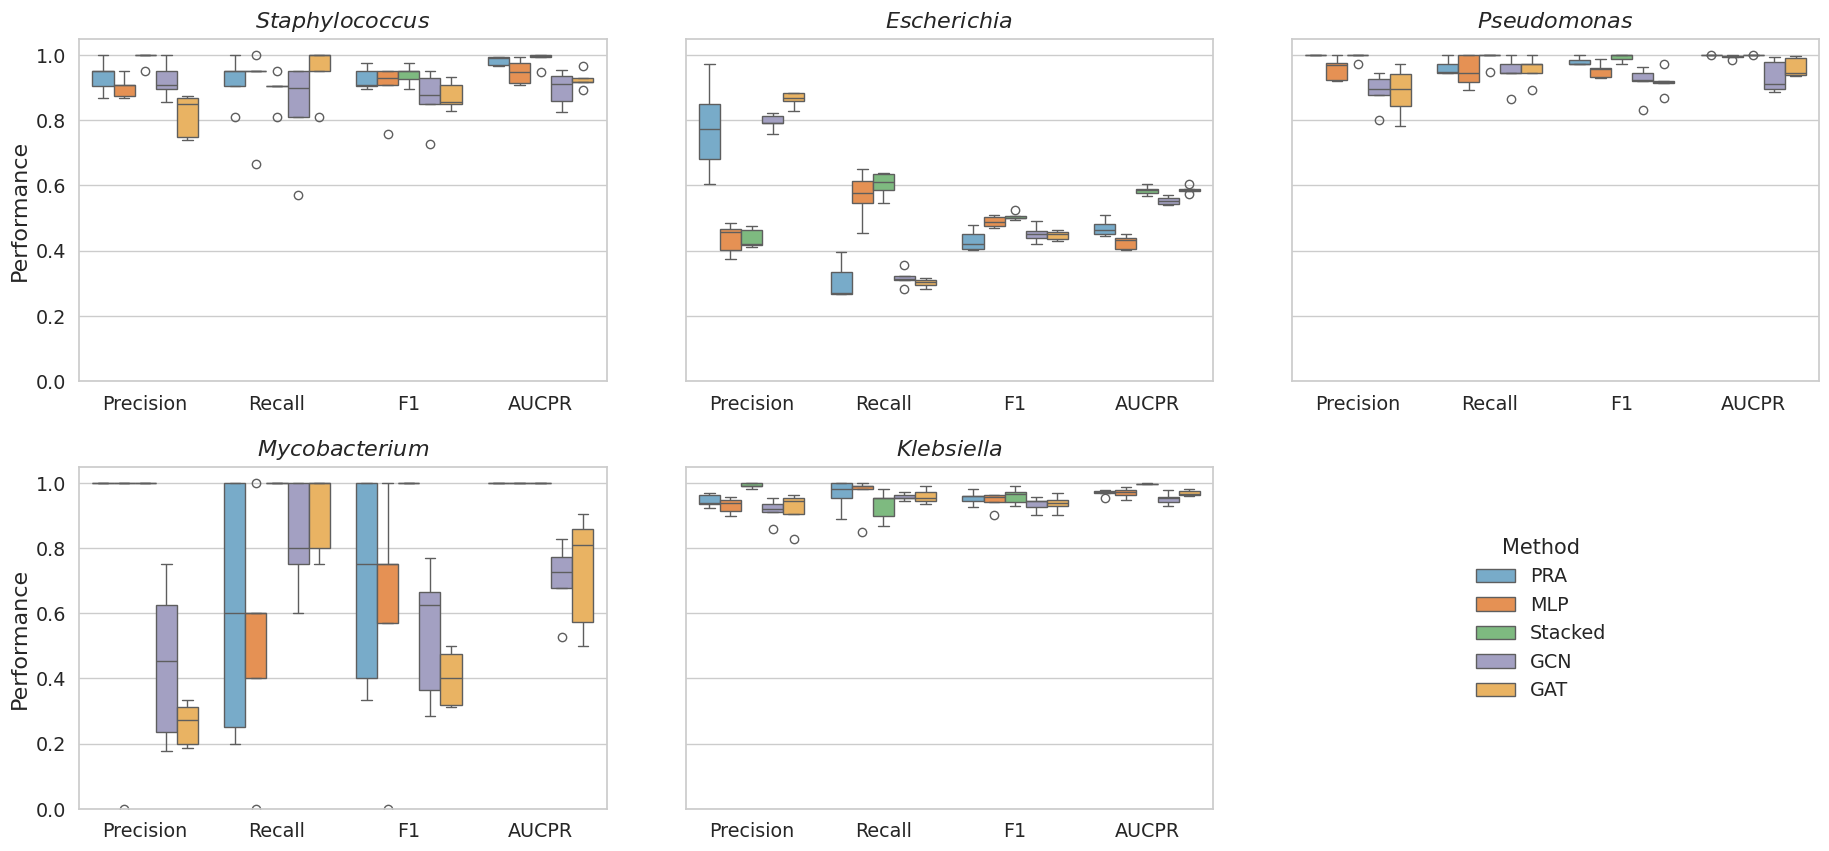

In [8]:
# plot the box plot for five species results
plot_figures.plot_strain_subplots_metrics_x(
    df_results,
    layout="2x3",
    strain_order=["Staphylococcus", "Escherichia", "Pseudomonas", "Mycobacterium", "Klebsiella"],
    add_points=False,
    ylim=(0, 1.05),
    savepath=f"{home_path}/figure/Figure1_AResKG_top5_species_boxplot.pdf"
)

### Scenario 2: AResKG_Ecoli vs KIDS

We compared model performance when trained and evaluated on our curated knowledge graph AResKG_Ecoli against the existing antibiotic resistance graph KIDS.

___

In [9]:
traditional_results_kids_path = f"{home_path}/results/1_performance_kids/traditional_models/kids"
traditional_results_areskg_path = f"{home_path}/results/1_performance_kids/traditional_models/areskg_ecoli"

gnn_result_kids_path = f"{home_path}/results/1_performance_kids/gnn_models/kids"
gnn_result_areskg_path = f"{home_path}/results/1_performance_kids/gnn_models/areskg_ecoli"

In [10]:
## import GNN results
df_list = [] 

df_gat_kids = data_process.parse_gcn_result_txt(
    f"{gnn_result_kids_path}/GAT_256_kg.txt", # GAT.txt",
    method_name="GAT",
    source_name="KIDS",
    keep_metrics=("precision", "recall", "f1")
)
df_gcn_kids = data_process.parse_gcn_result_txt(
    f"{gnn_result_kids_path}/GCN_256_kg.txt",
    method_name="GCN",
    source_name="KIDS",
    keep_metrics=("precision", "recall", "f1")
)

df_gat_areskg = data_process.parse_gcn_result_txt(
    f"{gnn_result_areskg_path}/GAT_256_kg.txt", # GAT.txt",
    method_name="GAT",
    source_name="AResKG_Ecoli",
    keep_metrics=("precision", "recall", "f1")
)

df_gcn_areskg = data_process.parse_gcn_result_txt(
    f"{gnn_result_areskg_path}/GCN_256_kg.txt",
    method_name="GCN",
    source_name="AResKG_Ecoli",
    keep_metrics=("precision", "recall", "f1")
)

df_list.extend([df_gat_kids, df_gcn_kids, df_gat_areskg, df_gcn_areskg])

df_gnn = pd.concat(df_list, ignore_index=True)
df_gnn.head(5)

,Method,Fold,Metric,Score,Source
0,GAT,fold_0,f1,0.236253,KIDS
1,GAT,fold_0,recall,0.181250,KIDS
2,GAT,fold_0,precision,0.339181,KIDS
3,GAT,fold_1,f1,0.155125,KIDS
4,GAT,fold_1,recall,0.087774,KIDS


In [11]:
methods = ["pra", "er_mlp", "stacked"]
folds = [f"fold_{i}" for i in range(5)]
metrics_of_interest = ["precision", "recall", "f1"]

df_kids = data_process.extract_predict_results(traditional_results_kids_path, strain="KIDS", methods=methods, folds=folds, metrics_of_interest=metrics_of_interest)
df_areskg = data_process.extract_predict_results(traditional_results_areskg_path, strain="AResKG_Ecoli", methods=methods, folds=folds, metrics_of_interest=metrics_of_interest)

In [12]:
# combine all the results
df_all = pd.concat([df_gnn, df_kids, df_areskg], ignore_index=True)

df_compare = df_all.pivot_table(
    index=["Method", "Fold", "Metric"],
    columns="Source",
    values="Score"
).reset_index()

In [13]:
name_map = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "map": "AUCPR"
}

method_map ={
    "pra": "PRA",
    "er_mlp": "MLP",
    "stacked": "Stacked",
    "gat": "GAT",
    "gcn": "GCN"
}
df_long = (df_compare.melt(id_vars=["Method", "Fold", "Metric"], value_vars=["KIDS", "AResKG_Ecoli"], var_name="Source", value_name="Score"))
df_long["Metric"] = (df_long["Metric"].astype(str).str.strip().str.lower().map(name_map))
df_long["Method"] = (df_long["Method"].astype(str).str.strip().str.lower().map(method_map))

In [14]:
method_order = ["PRA", "MLP", "Stacked", "GCN", "GAT"]
metric_order = ["Precision", "Recall", "F1"]

df_long["Method"] = pd.Categorical(df_long["Method"], categories=method_order, ordered=True)
df_long["Metric"] = pd.Categorical(df_long["Metric"], categories=metric_order, ordered=True)

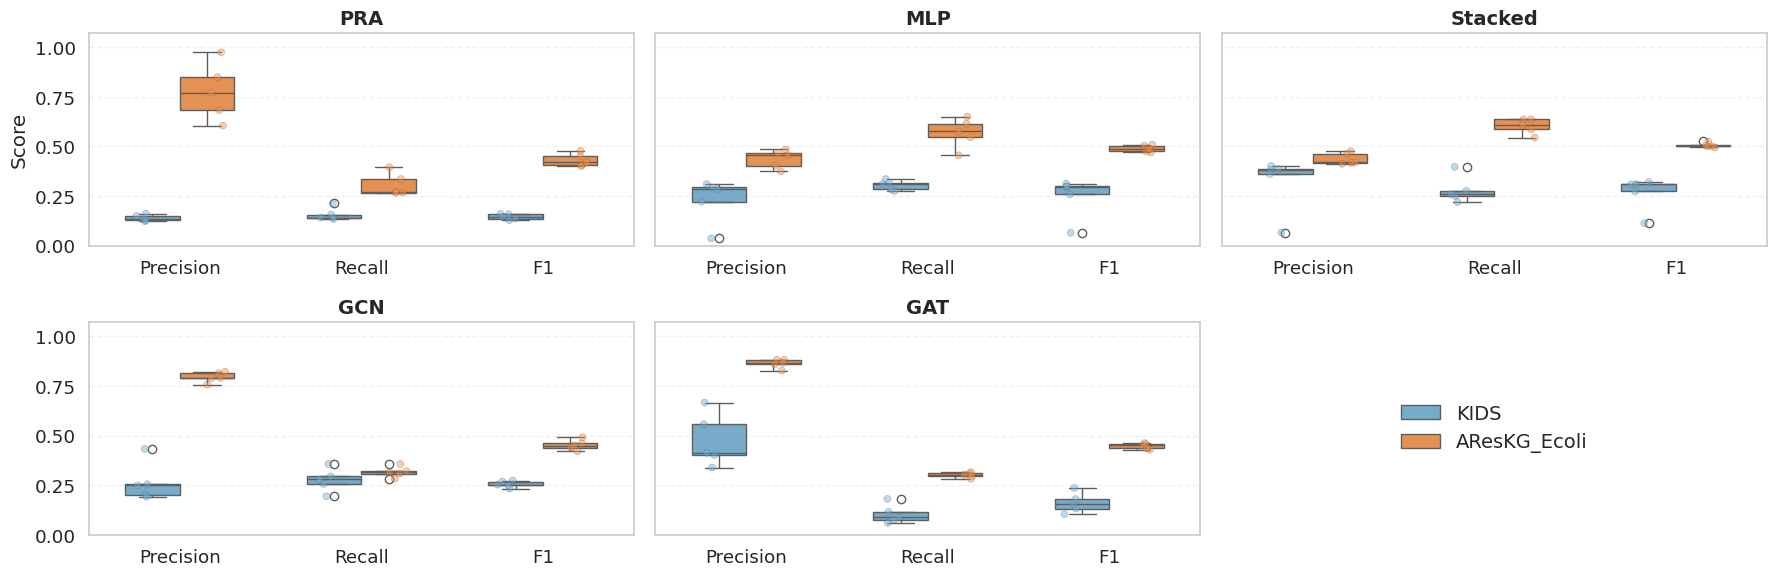

In [15]:
# ====== Plotting parameters ======
sns.set(style="whitegrid", font_scale=1.2)
palette = ["#6BAED6", "#FD8D3C"]  # Blue vs Orange
hue_order = ["KIDS", "AResKG_Ecoli"]
metrics_order = ["Precision", "Recall", "F1"]

# ====== Multiple subplots (2×3 grid, one subplot per Method) ======
methods = [m for m in method_order if (df_long["Method"] == m).any()]
n_methods = len(methods)
nrows, ncols = 2, 3

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3 * nrows), sharey=True)
axes = np.array(axes).flatten()

# Global y-axis upper limit
y_global_max = df_long["Score"].max(skipna=True)
y_top = max(1.0, (0 if pd.isna(y_global_max) else y_global_max) + 0.10)

for ax, method in zip(axes, methods):
    dfg = df_long[df_long["Method"] == method]

    sns.boxplot(
        data=dfg, x="Metric", y="Score",
        hue="Source", hue_order=hue_order,
        palette=palette, showfliers=True,
        width=0.6, ax=ax, order=metrics_order,
    )

    sns.stripplot(
        data=dfg, x="Metric", y="Score",
        hue="Source", hue_order=hue_order,
        dodge=True, alpha=0.45, size=5,
        linewidth=0.4, palette=palette,
        ax=ax, legend=False, order=metrics_order,
    )

    leg = ax.get_legend()
    if leg is not None:
        leg.remove()

    ax.set_title(method, fontsize=14, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Score" if ax is axes[0] else "")
    ax.set_ylim(0, y_top)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

# Hide empty subplots (if there are fewer than 6 methods)
for j in range(len(methods), len(axes)):
    axes[j].axis("off")

# Global legend (top-right corner)
handles, labels = axes[0].get_legend_handles_labels()
if len(handles) >= 2 and len(axes) >= 6:
    legend_ax = axes[5]  # 6th subplot (row 2, column 3)
    legend_ax.axis("off")  # hide axes
    legend_ax.legend(
        handles[:2], labels[:2],
        frameon=False,
        loc="center",
        bbox_to_anchor=(0.5, 0.5),
        fontsize=14,
    )

plt.subplots_adjust(wspace=0.25, hspace=0.35, right=0.95, top=0.92, bottom=0.10)
plt.tight_layout()
plt.savefig(f"{home_path}/figure/Figure2_Box_plot_compare.pdf", dpi=300, bbox_inches="tight")
plt.show()